# Data preparation

Load ATP match data from `research/data/raw`, concatenate all yearly files (2004–2026), and build the research dataset. This notebook writes only `research/data/output/matches_2015_onwards.csv`; deployment-facing player and head-to-head artifacts are intentionally out of scope.

In [1]:
from pathlib import Path

import pandas as pd

WORKING_DIR = Path.cwd().resolve()
RESEARCH_DIR = WORKING_DIR if WORKING_DIR.name == "research" else WORKING_DIR / "research"
if not RESEARCH_DIR.is_dir():
    raise FileNotFoundError(
        "Run this notebook from the project root or the research directory."
    )

RAW_DIR = RESEARCH_DIR / "data" / "raw"

In [2]:
def load_raw_files(raw_dir: Path = RAW_DIR) -> list[pd.DataFrame]:
    """Load each Excel file in raw_dir and attach the source year."""
    data_files = sorted(
        p for p in raw_dir.iterdir()
        if p.suffix.lower() in {".xls", ".xlsx"}
    )

    frames = []
    for path in data_files:
        year = int(path.stem)
        df = pd.read_excel(path, sheet_name=0)
        df["year"] = year
        df["source_file"] = path.name
        frames.append(df)
        print(f"Loaded {path.name}: {len(df):,} rows, {len(df.columns)} columns")

    return frames

In [3]:
frames = load_raw_files()
matches_df = pd.concat(frames, ignore_index=True, sort=False)

# Some raw rows pad player names with trailing spaces. Left alone, those rows
# become separate rating identities and restart the affected player at the
# initial Elo.
for name_column in ["Winner", "Loser"]:
    matches_df[name_column] = matches_df[name_column].str.strip()
    assert matches_df[name_column].equals(matches_df[name_column].str.strip())

print(f"\nCombined DataFrame: {matches_df.shape[0]:,} rows × {matches_df.shape[1]} columns")
print(f"Distinct player names: {len(set(matches_df['Winner']) | set(matches_df['Loser'])):,}")

Loaded 2004.xls: 2,877 rows, 38 columns
Loaded 2005.xls: 2,909 rows, 40 columns
Loaded 2006.xls: 2,909 rows, 40 columns


Loaded 2007.xls: 2,806 rows, 40 columns
Loaded 2008.xls: 2,707 rows, 40 columns
Loaded 2009.xls: 2,731 rows, 40 columns


Loaded 2010.xls: 2,679 rows, 44 columns
Loaded 2011.xls: 2,675 rows, 44 columns
Loaded 2012.xls: 2,607 rows, 44 columns


/Users/nick/Library/Python/3.9/lib/python/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


Loaded 2013.xlsx: 2,631 rows, 44 columns


/Users/nick/Library/Python/3.9/lib/python/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


... (10 outputs left out)

Loaded 2023.xlsx: 2,703 rows, 38 columns


Loaded 2024.xlsx: 2,703 rows, 38 columns


Loaded 2025.xlsx: 2,644 rows, 40 columns


Loaded 2026.xlsx: 1,881 rows, 40 columns

Combined DataFrame: 59,586 rows × 52 columns
Distinct player names: 1,522


In [4]:
matches_df.head()

,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,Winner,...,LBW,LBL,SJW,SJL,MaxW,MaxL,AvgW,AvgL,BFEW,BFEL
0,1,Adelaide,AAPT Championships,2004-01-05,International,Outdoor,Hard,1st Round,3.0,Spadea V.,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Adelaide,AAPT Championships,2004-01-05,International,Outdoor,Hard,1st Round,3.0,Dent T.,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,Adelaide,AAPT Championships,2004-01-05,International,Outdoor,Hard,1st Round,3.0,Martin A.,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,Adelaide,AAPT Championships,2004-01-05,International,Outdoor,Hard,1st Round,3.0,Beck K.,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,Adelaide,AAPT Championships,2004-01-05,International,Outdoor,Hard,1st Round,3.0,Nieminen J.,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
matches_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59586 entries, 0 to 59585
Data columns (total 52 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   ATP          59586 non-null  int64         
 1   Location     59586 non-null  object        
 2   Tournament   59586 non-null  object        
 3   Date         59586 non-null  datetime64[ns]
 4   Series       59586 non-null  object        
 5   Court        59586 non-null  object        
 6   Surface      59586 non-null  object        
 7   Round        59586 non-null  object        
 8   Best of      59571 non-null  float64       
 9   Winner       59586 non-null  object        
 10  Loser        59586 non-null  object        
 11  WRank        59565 non-null  float64       
 12  LRank        59468 non-null  float64       
 13  W1           59229 non-null  object        
 14  L1           59231 non-null  object        
 15  W2           58699 non-null  object        
 16  L2  

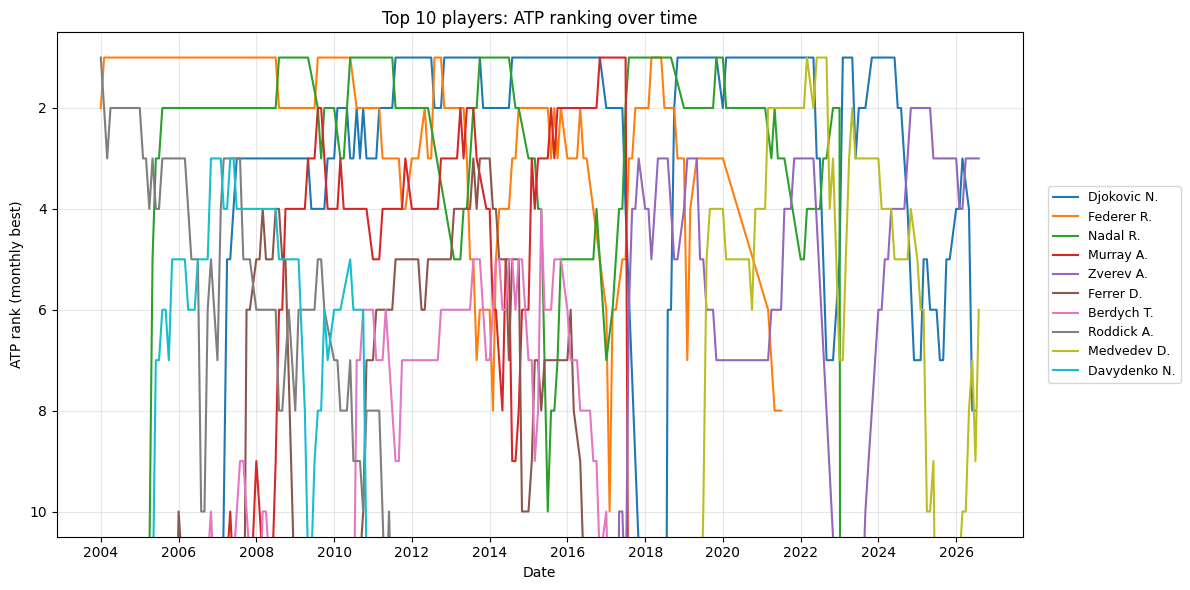

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

completed = matches_df[matches_df["Comment"] == "Completed"].copy()
completed["sets_played"] = completed["Wsets"] + completed["Lsets"]

rank_history = pd.concat(
    [
        completed[["Date", "Winner", "WRank"]].rename(
            columns={"Winner": "player", "WRank": "rank"}
        ),
        completed[["Date", "Loser", "LRank"]].rename(
            columns={"Loser": "player", "LRank": "rank"}
        ),
    ],
    ignore_index=True,
)
rank_history = rank_history.dropna(subset=["rank"])
rank_history["Date"] = pd.to_datetime(rank_history["Date"])

top10_players = (
    rank_history[rank_history["rank"] <= 10]
    .groupby("player")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .index.tolist()
)

monthly_ranks = (
    rank_history[rank_history["player"].isin(top10_players)]
    .assign(month=lambda d: d["Date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["player", "month"])["rank"]
    .min()
    .reset_index()
    .rename(columns={"month": "Date"})
)

fig, ax = plt.subplots(figsize=(12, 6))

for player in top10_players:
    player_data = monthly_ranks[monthly_ranks["player"] == player]
    ax.plot(player_data["Date"], player_data["rank"], label=player, linewidth=1.5)

ax.invert_yaxis()
ax.set_ylim(10.5, 0.5)
ax.set_ylabel("ATP rank (monthly best)")
ax.set_xlabel("Date")
ax.set_title("Top 10 players: ATP ranking over time")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

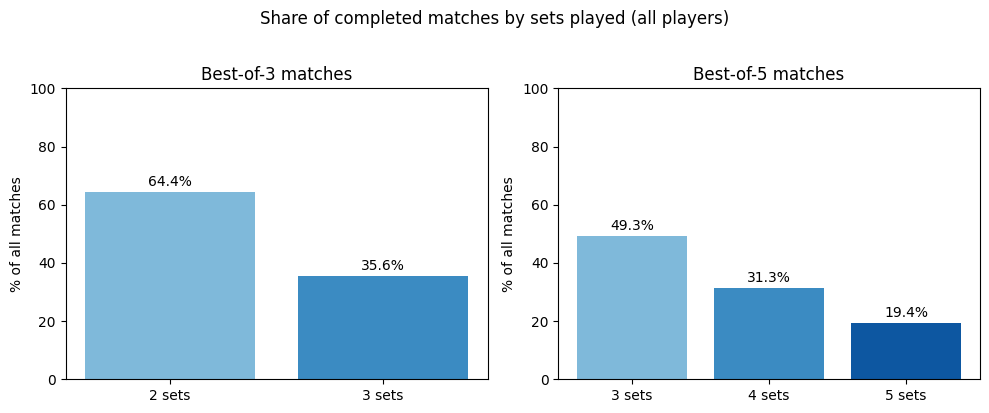

Best-of-3: 46,399 matches  →  2 sets: 64.4%  |  3 sets: 35.6%
Best-of-5: 10,954 matches  →  3 sets: 49.3%  |  4 sets: 31.3%  |  5 sets: 19.4%


In [7]:
def sets_share(completed_df: pd.DataFrame, best_of: int, valid_sets: list[int]) -> tuple[pd.Series, int]:
    subset = completed_df[
        (completed_df["Best of"] == best_of)
        & (completed_df["sets_played"].isin(valid_sets))
    ]
    counts = subset["sets_played"].value_counts().reindex(valid_sets, fill_value=0)
    return counts / counts.sum() * 100, len(subset)


bo3_share, bo3_n = sets_share(completed, best_of=3, valid_sets=[2, 3])
bo5_share, bo5_n = sets_share(completed, best_of=5, valid_sets=[3, 4, 5])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, share, title, labels in [
    (axes[0], bo3_share, "Best-of-3 matches", ["2 sets", "3 sets"]),
    (axes[1], bo5_share, "Best-of-5 matches", ["3 sets", "4 sets", "5 sets"]),
]:
    bars = ax.bar(labels, share.values, color=plt.cm.Blues([0.45, 0.65, 0.85][: len(labels)]))
    ax.set_ylabel("% of all matches")
    ax.set_ylim(0, 100)
    ax.set_title(title)
    for bar, pct in zip(bars, share.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{pct:.1f}%",
            ha="center",
            va="bottom",
            fontsize=10,
        )

plt.suptitle("Share of completed matches by sets played (all players)", y=1.02)
plt.tight_layout()
plt.show()

print(f"Best-of-3: {bo3_n:,} matches  →  2 sets: {bo3_share.iloc[0]:.1f}%  |  3 sets: {bo3_share.iloc[1]:.1f}%")
print(f"Best-of-5: {bo5_n:,} matches  →  3 sets: {bo5_share.iloc[0]:.1f}%  |  4 sets: {bo5_share.iloc[1]:.1f}%  |  5 sets: {bo5_share.iloc[2]:.1f}%")

## Research dataset export

Filter to 2015 onwards, retain only Bet365 and Pinnacle among bookmaker odds, and save the prepared matches to `research/data/output`. No top-level or deployment artifact is produced.

In [8]:
OUTPUT_DIR = RESEARCH_DIR / "data" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

KEEP_ODDS = {"B365W", "B365L", "PSW", "PSL"}
ODDS_COLUMNS = {
    "B365W", "B365L", "CBW", "CBL", "EXW", "EXL", "IWW", "IWL",
    "LBW", "LBL", "PSW", "PSL", "SJW", "SJL", "UBW", "UBL",
    "MaxW", "MaxL", "AvgW", "AvgL", "BFEW", "BFEL",
}
DROP_ODDS = ODDS_COLUMNS - KEEP_ODDS

export_df = (
    matches_df.loc[matches_df["year"] >= 2015]
    .drop(columns=[c for c in DROP_ODDS if c in matches_df.columns])
)

output_path = OUTPUT_DIR / "matches_2015_onwards.csv"
assert output_path.resolve().parent == OUTPUT_DIR.resolve()
export_df.to_csv(output_path, index=False)

print(f"Exported {len(export_df):,} rows × {export_df.shape[1]} columns")
print(f"Saved to {output_path.resolve()}")
print(f"Dropped odds columns: {sorted(DROP_ODDS)}")

Exported 29,455 rows × 34 columns
Saved to /Users/nick/Desktop/tennis live/research/data/output/matches_2015_onwards.csv
Dropped odds columns: ['AvgL', 'AvgW', 'BFEL', 'BFEW', 'CBL', 'CBW', 'EXL', 'EXW', 'IWL', 'IWW', 'LBL', 'LBW', 'MaxL', 'MaxW', 'SJL', 'SJW', 'UBL', 'UBW']


In [9]:
# Research-only boundary
#
# Head-to-head and player-profile deployment artifacts are not created here.
# This notebook's only write is the prepared match CSV under research/data/output.